In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import atmosfera
import stella
import sensore

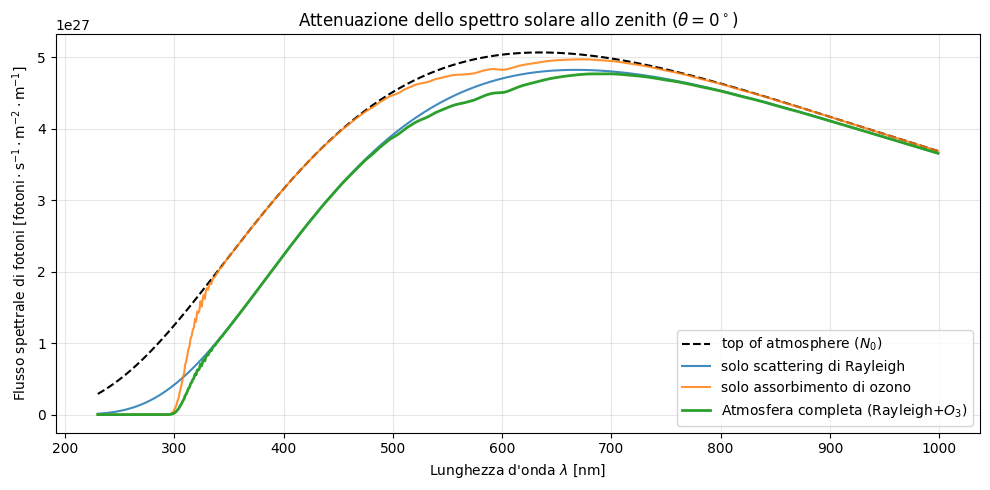

In [5]:
delta_lambda = 1e-9
wavelength = np.arange(230e-9, 1000e-9, delta_lambda)
sole = stella.CorpoNero('sole', 5778.0, 6.96e8, 1.496e11)
N0=sole.toa_flusso_fotoni(wavelength)

file_o3 = 'SCIA_O3_Temp_cross-section_V4.1.DAT'
atm_rayleigh =  atmosfera.Atmosfera(enable_rayleigh=True, enable_ozone=False)
atm_ozono = atmosfera.Atmosfera(enable_rayleigh=False, enable_ozone=True, percorso_file_O3 = file_o3)
atm_completa = atmosfera.Atmosfera(enable_rayleigh=True, enable_ozone=True, percorso_file_O3 = file_o3)

N_rayleigh = atm_rayleigh.N_obs(N0, wavelength, 0.0)
N_ozono = atm_ozono.N_obs(N0, wavelength, 0.0)
N_completa = atm_completa.N_obs(N0, wavelength, 0.0)

wl_nm=wavelength*1e9
plt.figure(figsize=(10,5))
plt.plot(wl_nm, N0, label="top of atmosphere ($N_0$)", color='black', linestyle='--')
plt.plot(wl_nm, N_rayleigh, label='solo scattering di Rayleigh', alpha=0.85)
plt.plot(wl_nm, N_ozono, label='solo assorbimento di ozono', alpha=0.85)
plt.plot(wl_nm, N_completa, label='Atmosfera completa (Rayleigh+$O_3$)', linewidth=2)
plt.xlabel("Lunghezza d'onda $\\lambda$ [nm]")
plt.ylabel("Flusso spettrale di fotoni [$\\mathrm{fotoni \\cdot s^{-1} \\cdot m^{-2} \\cdot m^{-1}}$]")
plt.title('Attenuazione dello spettro solare allo zenith ($\\theta = 0^\\circ$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


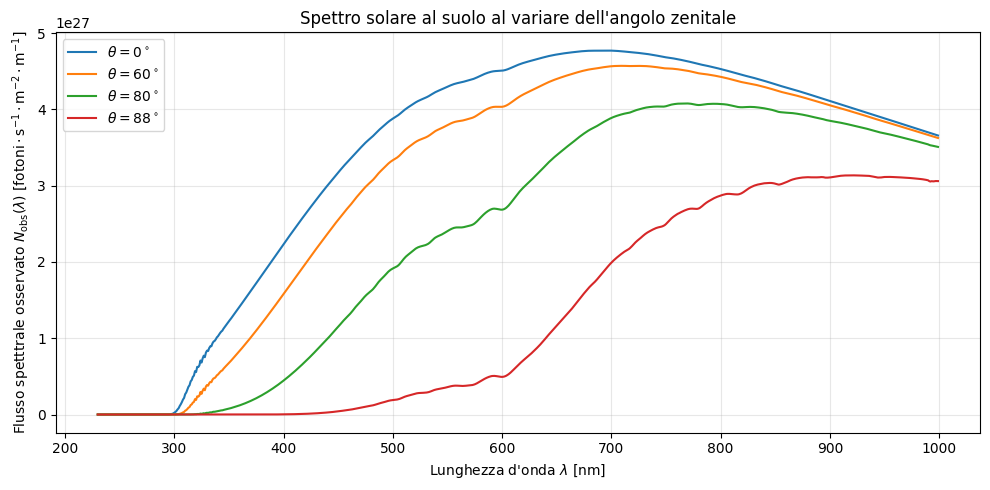

In [6]:
angoli = [0.0, 60.0, 80.0, 88.0]
plt.figure(figsize=(10,5))
for theta in angoli:
    N_theta = atm_completa.N_obs(N0, wavelength, theta)
    plt.plot(wl_nm, N_theta, label=f"$\\theta = {theta:.0f}^\\circ$")
plt.xlabel("Lunghezza d'onda $\\lambda$ [nm]")
plt.ylabel("Flusso spetttrale osservato $N_{\\mathrm{obs}}(\\lambda)$ [$\\mathrm{fotoni \\cdot s^{-1} \\cdot m^{-2} \\cdot m^{-1}}$]")
plt.title("Spettro solare al suolo al variare dell'angolo zenitale")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()